# AF5. Simulación de un péndulo-robot

FIME–UANL · Modelado y Simulación de Sistemas Mecatrónicos · Grupo 004, V6.

## Objetivo y supuestos
Derivar el modelo con Euler–Lagrange y simular 10 s. Parámetros de AF5_Modelado.pdf. Se adopta un par constante de **1 N·m**, no proporcionado por el enunciado, y ángulo desde la vertical inferior. Se interpreta Ir como inercia respecto del eje de articulación. La fricción de Coulomb se regulariza con tanh; no se modela adherencia estática exacta.

## Modelo
$$I_r\ddot\theta+b\dot\theta+mgl_c\sin\theta+f_c\operatorname{sgn}(\dot\theta)=\tau(t).$$
Con $x_1=\theta$, $x_2=\dot\theta$, se integra $\dot x_1=x_2$ y $\dot x_2=[\tau-bx_2-mgl_c\sin(x_1)-f_c\tanh(x_2/\varepsilon)]/I_r$.

El archivo requirements.txt contiene las dependencias. En Colab normalmente ya están disponibles.

## 1. Parámetros y ecuaciones

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import scipy
Ir, m, g, lc, b, fc = 0.16, 5.0, 9.81, 0.01, 0.14, 0.45
tau0 = 1.0  # N m: supuesto de trabajo, no especificado en la consigna
eps = 0.001  # rad/s, regularizacion de Coulomb
t = np.linspace(0.0, 10.0, 2001)
x0 = [0.0, 0.0]
def torque(t):
    return tau0
def modelo(t, x, epsilon=eps):
    theta, omega = x
    return [omega, (torque(t)-b*omega-fc*np.tanh(omega/epsilon)
                    -m*g*lc*np.sin(theta))/Ir]
print('NumPy:', np.__version__, '| SciPy:', scipy.__version__)


NumPy: 2.3.5 | SciPy: 1.18.1


## 2. Integración numérica

In [2]:
sol = solve_ivp(modelo, (0, 10), x0, t_eval=t, rtol=1e-9, atol=1e-11, max_step=0.01)
assert sol.success, sol.message
theta, omega = sol.y
print(f'Posicion a 10 s: {theta[-1]:.6f} rad ({np.degrees(theta[-1]):.3f} grados)')
print(f'Velocidad a 10 s: {omega[-1]:.6f} rad/s')
print(f'Velocidad maxima muestreada: {omega.max():.6f} rad/s')


Posicion a 10 s: 29.194922 rad (1672.746 grados)
Velocidad a 10 s: 3.638357 rad/s
Velocidad maxima muestreada: 4.654989 rad/s


## 3. Posición y velocidad

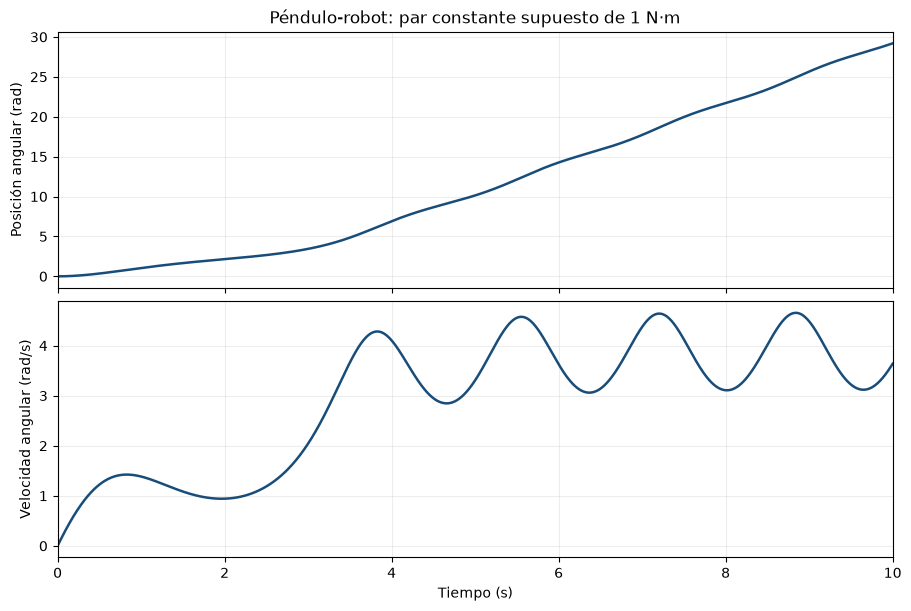

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True, constrained_layout=True)
for ax, y, label in zip(axes, [theta, omega], ['Posición angular (rad)', 'Velocidad angular (rad/s)']):
    ax.plot(t, y, color='#184d7a', linewidth=1.8)
    ax.set_ylabel(label); ax.grid(alpha=0.22); ax.set_xlim(0,10)
axes[0].set_title('Péndulo-robot: par constante supuesto de 1 N·m')
axes[1].set_xlabel('Tiempo (s)')
plt.show()


## 4. Comprobaciones numéricas y físicas

In [4]:
ref = solve_ivp(modelo, (0,10), x0, t_eval=t, rtol=1e-11, atol=1e-13, max_step=0.005)
error = np.max(np.abs(sol.y-ref.y),axis=1)
assert ref.success and np.all(error < 1e-5)
print('Diferencias máximas con tolerancia más estricta [rad, rad/s]:', error)
for epsilon in [0.002, 0.0005]:
    alt = solve_ivp(lambda tt,xx: modelo(tt,xx,epsilon), (0,10), x0,
                    t_eval=t, rtol=1e-9, atol=1e-11, max_step=0.01)
    assert alt.success
    print('epsilon:',epsilon,'; diferencia máxima [rad, rad/s]:', np.max(np.abs(sol.y-alt.y),axis=1))
# Comprobación independiente: trabajo del motor = energía + disipación.
from scipy.integrate import cumulative_trapezoid
energia = 0.5*Ir*omega**2 + m*g*lc*(1-np.cos(theta))
potencia = tau0*omega - b*omega**2 - fc*np.tanh(omega/eps)*omega
residuo = energia - cumulative_trapezoid(potencia,t,initial=0)
assert np.max(np.abs(residuo)) < 1e-3
print('Residuo máximo de balance energético (J):', np.max(np.abs(residuo)))
reposo = solve_ivp(lambda tt,xx: [xx[1],(-b*xx[1]-fc*np.tanh(xx[1]/eps)-m*g*lc*np.sin(xx[0]))/Ir],
                   (0,10), x0, t_eval=t)
assert np.allclose(reposo.y,0)
print('Sin par y desde el equilibrio: posición y velocidad permanecen en cero.')


Diferencias máximas con tolerancia más estricta [rad, rad/s]: [5.86197757e-12 8.48832116e-12]
epsilon: 0.002 ; diferencia máxima [rad, rad/s]: [0.0005442  0.00041443]


epsilon: 0.0005 ; diferencia máxima [rad, rad/s]: [0.00027169 0.0002069 ]
Residuo máximo de balance energético (J): 8.16337164066816e-06
Sin par y desde el equilibrio: posición y velocidad permanecen en cero.


## Interpretación
A los 10 s: posición 29.1949 rad y velocidad 3.6384 rad/s. La posición no está envuelta a ±π. El motor permite rotaciones completas: 1 N·m supera la suma de la fricción de Coulomb y el par gravitacional máximo, 0.9405 N·m. No es una respuesta regulada a una posición deseada.

## Referencias
- Consigna AF5_Modelado.pdf, proporcionada por el docente.
- Tedrake, R. Underactuated Robotics, The Simple Pendulum: https://underactuated.mit.edu/pend.html
- SciPy. solve_ivp: https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html

## Reproducción
Abrir esta notebook en Jupyter o Google Colab y ejecutar todas las celdas en orden. Las gráficas y los resultados guardados corresponden al par supuesto de 1 N·m. La conclusión grupal se completa en el documento de Prism.